In [25]:
import pandas as pd
import numpy as np
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt

In [26]:
from data_processing import import_data

In [27]:
lf = import_data()

# General statistics

In [4]:
for col in ['delta_days', 'sales_net', 'quantity']:

    print('_________________________________________')
    print(f"Statistiques pour la colonne {col}:")
    stats = lf.select(
        pl.col(col).count().alias("nb_valides"),
        pl.col(col).null_count().alias("nb_nulls"),
        pl.col(col).mean().alias("moyenne"),
        pl.col(col).std().alias("ecart_type"),
        pl.col(col).min().alias("min"),
        pl.col(col).median().alias("mediane"),
        pl.col(col).max().alias("max"),
    ).collect(engine="streaming")

    print(stats)

_________________________________________
Statistiques pour la colonne delta_days:
shape: (1, 7)
┌────────────┬──────────┬──────────┬────────────┬──────┬─────────┬──────┐
│ nb_valides ┆ nb_nulls ┆ moyenne  ┆ ecart_type ┆ min  ┆ mediane ┆ max  │
│ ---        ┆ ---      ┆ ---      ┆ ---        ┆ ---  ┆ ---     ┆ ---  │
│ u32        ┆ u32      ┆ f64      ┆ f64        ┆ i64  ┆ f64     ┆ i64  │
╞════════════╪══════════╪══════════╪════════════╪══════╪═════════╪══════╡
│ 63319314   ┆ 1        ┆ 5.060313 ┆ 19.921085  ┆ -406 ┆ 0.0     ┆ 1302 │
└────────────┴──────────┴──────────┴────────────┴──────┴─────────┴──────┘
_________________________________________
Statistiques pour la colonne sales_net:
shape: (1, 7)
┌────────────┬──────────┬────────────┬────────────┬───────────┬─────────┬────────────┐
│ nb_valides ┆ nb_nulls ┆ moyenne    ┆ ecart_type ┆ min       ┆ mediane ┆ max        │
│ ---        ┆ ---      ┆ ---        ┆ ---        ┆ ---       ┆ ---     ┆ ---        │
│ u32        ┆ u32      ┆ f6

shape: (5, 6)
┌─────────────────────────────────┬───────────┬──────────┬────────────┬────────────┬────────┐
│ order_channel                   ┆ nb_lignes ┆ ca       ┆ nb_clients ┆ pct_lignes ┆ pct_ca │
│ ---                             ┆ ---       ┆ ---      ┆ ---        ┆ ---        ┆ ---    │
│ str                             ┆ u32       ┆ f64      ┆ u32        ┆ f64        ┆ f64    │
╞═════════════════════════════════╪═══════════╪══════════╪════════════╪════════════╪════════╡
│ at the store                    ┆ 32114196  ┆ 2.4501e9 ┆ 146857     ┆ 50.72      ┆ 26.16  │
│ by phone                        ┆ 25465205  ┆ 6.0301e9 ┆ 135602     ┆ 40.22      ┆ 64.37  │
│ online                          ┆ 5651866   ┆ 8.7102e8 ┆ 21352      ┆ 8.93       ┆ 9.3    │
│ other                           ┆ 58735     ┆ 8.8495e6 ┆ 8811       ┆ 0.09       ┆ 0.09   │
│ during the visit of a sales re… ┆ 29313     ┆ 7.4432e6 ┆ 1203       ┆ 0.05       ┆ 0.08   │
└─────────────────────────────────┴───────────

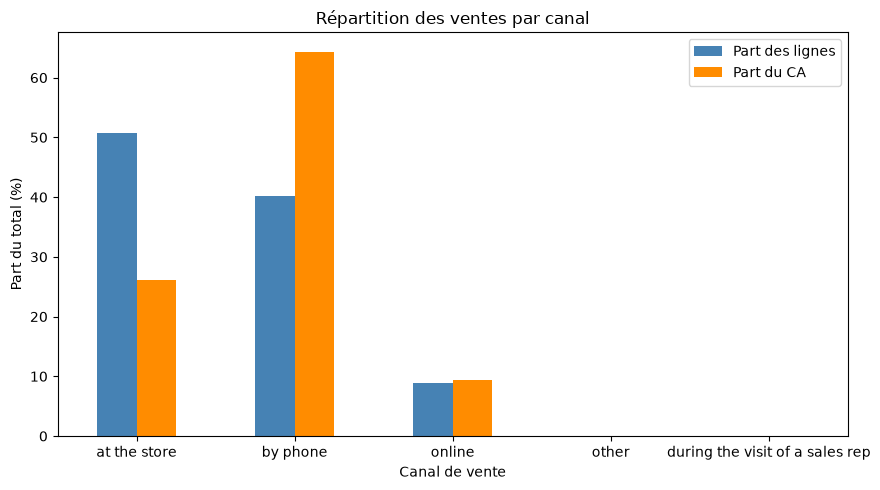

In [5]:
repartition = (
    lf
    .with_columns(
        pl.col("order_channel").fill_null("Non renseigné")
    )
    .group_by("order_channel")
    .agg(
        pl.len().alias("nb_lignes"),
        pl.col("sales_net").sum().alias("ca"),
        pl.col("client_id").drop_nulls().n_unique().alias("nb_clients"),
    )
    .with_columns(
        (100 * pl.col("nb_lignes") / pl.col("nb_lignes").sum())
        .round(2).alias("pct_lignes"),

        (100 * pl.col("ca") / pl.col("ca").sum())
        .round(2).alias("pct_ca"),
    )
    .sort("nb_lignes", descending=True)
    .collect(engine="streaming")
)

print(repartition)

r = repartition.to_pandas().set_index("order_channel")

r[["pct_lignes", "pct_ca"]].plot.bar(
    figsize=(9, 5),
    color=["steelblue", "darkorange"],
    rot=0,
)

plt.title("Répartition des ventes par canal")
plt.xlabel("Canal de vente")
plt.ylabel("Part du total (%)")
plt.legend(["Part des lignes", "Part du CA"])
plt.tight_layout()
plt.show()

# Exploration des habitudes client

In [ ]:
from churn_features import construire_quotidien

# Achats positifs uniquement ; produits, agences et canaux conservés par jour.
quotidien = construire_quotidien(lf)

In [ ]:
# Date de référence de l'analyse : fin de l'historique disponible
date_fin = quotidien.select(pl.col("date").max()).collect().item()

intervalles = (
    quotidien
    .sort(["client_id", "date"])
    .with_columns(
        pl.col("date")
        .diff()
        .over("client_id")
        .dt.total_days()
        .alias("intervalle_j")
    )
)

profils = (
    intervalles
    .group_by("client_id")
    .agg(
        pl.col("date").min().alias("premier_achat"),
        pl.col("date").max().alias("dernier_achat"),
        pl.len().alias("nb_jours_achat"),
        pl.col("ca_achats").sum().alias("ca_total"),
        pl.col("intervalle_j").median().alias("intervalle_median_j"),
        pl.col("intervalle_j").mean().alias("intervalle_moyen_j"),
        pl.col("intervalle_j").std().alias("intervalle_std_j"),
        pl.col("intervalle_j").max().alias("intervalle_max_j"),
    )
    .with_columns(
        (pl.lit(date_fin) - pl.col("premier_achat"))
        .dt.total_days().alias("anciennete_j"),

        (pl.lit(date_fin) - pl.col("dernier_achat"))
        .dt.total_days().alias("recence_j"),

        (pl.col("intervalle_std_j") / pl.col("intervalle_moyen_j"))
        .alias("cv_intervalles"),

        (pl.col("ca_total") / pl.col("nb_jours_achat"))
        .alias("ca_par_jour_achat"),
    )
    .with_columns(
        (pl.col("recence_j") / pl.col("intervalle_median_j"))
        .alias("retard_relatif")
    )
    .collect(engine="streaming")
)

print(f"Clients étudiés : {profils.height:,}")

stats = (
    profils
    .select(
        "nb_jours_achat",
        "anciennete_j",
        "recence_j",
        "intervalle_median_j",
        "cv_intervalles",
        "retard_relatif",
        "ca_total",
    )
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95])
    .with_columns(
        pl.col(pl.Float64).round(2)
    )
)

# Afficher toutes les lignes et colonnes du résumé
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    print(stats)

In [ ]:
from matplotlib.ticker import PercentFormatter, ScalarFormatter

# profils est le DataFrame Polars obtenu après .collect()
observables = profils.filter(pl.col("anciennete_j") >= 90)

repetes = observables.filter(
    (pl.col("nb_jours_achat") >= 5)
    & (pl.col("intervalle_median_j") > 0)
    & pl.col("cv_intervalles").is_finite()
    & pl.col("retard_relatif").is_finite()
)

print(f"Clients au total : {profils.height:,}")
print(f"Historique ≥ 90 jours : {observables.height:,}")
print(f"Rythme analysable : {repetes.height:,}")

if observables.height == 0 or repetes.height == 0:
    raise ValueError("Pas assez de clients avec les critères retenus.")

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(19, 11))


# Fonction : distribution en % avec classes logarithmiques
def histogramme_log(ax, valeurs, titre, xlabel, couleur):
    x = np.asarray(valeurs, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]

    if len(x) == 0:
        ax.set_title(titre)
        ax.text(0.5, 0.5, "Aucune donnée", ha="center",
                transform=ax.transAxes)
        return

    bins = np.geomspace(
        max(0.5, x.min() * 0.9),
        x.max() * 1.1,
        30,
    )

    ax.hist(
        x,
        bins=bins,
        weights=np.full(len(x), 100 / len(x)),
        color=couleur,
        edgecolor="white",
    )
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.set(title=titre, xlabel=xlabel, ylabel="Part des clients")


# 1. Nombre de jours d'achat
histogramme_log(
    axes[0, 0],
    observables["nb_jours_achat"].to_numpy(),
    "1. Combien de jours les clients ont-ils acheté ?",
    "Jours d'achat sur l'historique — axe logarithmique",
    "#4472C4",
)


# 2. Intervalle habituel entre deux jours d'achat
histogramme_log(
    axes[0, 1],
    repetes["intervalle_median_j"].to_numpy(),
    "2. À quel rythme les clients reviennent-ils ?",
    "Intervalle médian en jours — axe logarithmique",
    "#2A9D8F",
)


# 3. Régularité : distribution cumulée du CV
cv = np.sort(repetes["cv_intervalles"].to_numpy())
part_cumulee = 100 * np.arange(1, len(cv) + 1) / len(cv)

axes[0, 2].step(cv, part_cumulee, where="post", color="#8E5EA2")
# axes[0, 2].set_xscale("symlog", linthresh=0.1)
axes[0, 2].yaxis.set_major_formatter(PercentFormatter(100))
axes[0, 2].set(
    title="3. Quelle proportion a un rythme régulier ?",
    xlabel="CV des intervalles — faible = rythme stable",
    ylabel="Part des clients ayant un CV ≤ x",
    ylim=(0, 100),
)


# 4. Silence actuel rapporté au rythme habituel
retards = repetes["retard_relatif"].to_numpy()
bornes = [0, 1, 2, 3, 5, np.inf]
effectifs, _ = np.histogram(retards, bins=bornes)
parts = 100 * effectifs / len(retards)

ax = axes[1, 0]
barres = ax.bar(
    ["< 1×", "1–2×", "2–3×", "3–5×", "≥ 5×"],
    parts,
    color=["#2A9D8F", "#8AB17D", "#E9C46A", "#F4A261", "#E76F51"],
)
ax.bar_label(barres, labels=[f"{v:.1f} %" for v in parts], padding=3)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set(
    title="4. Le silence actuel dépasse-t-il le rythme habituel ?",
    xlabel="Jours depuis le dernier achat / intervalle médian",
    ylabel="Part des clients",
)
ax.margins(y=0.15)


# 5. Fréquence et régularité : échantillon pour garder un graphe léger
echantillon = repetes.sample(
    n=min(10_000, repetes.height),
    seed=42,
)

ax = axes[1, 1]
ax.scatter(
    echantillon["intervalle_median_j"].to_numpy(),
    echantillon["cv_intervalles"].to_numpy(),
    s=8,
    alpha=0.15,
    color="#4472C4",
    edgecolors="none",
)
ax.set_xscale("log")
ax.set_ylim(0, 10)
ax.set_yscale("symlog", linthresh=0.1)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set(
    title=f"5. Fréquence et régularité — {echantillon.height:,} clients",
    xlabel="Intervalle médian en jours → achats plus espacés",
    ylabel="CV des intervalles → rythme plus irrégulier",
)


# 6. Concentration du CA — tous les clients avec CA strictement positif
ca = (
    profils
    .filter(pl.col("ca_total").is_finite() & (pl.col("ca_total") > 0))
    .sort("ca_total", descending=True)
    ["ca_total"]
    .to_numpy()
)

ax = axes[1, 2]

if len(ca) > 0:
    part_clients = 100 * np.arange(1, len(ca) + 1) / len(ca)
    part_ca = 100 * np.cumsum(ca) / ca.sum()

    ax.plot(
        np.r_[0, part_clients],
        np.r_[0, part_ca],
        color="#E76F51",
        linewidth=2,
    )
    ax.plot([0, 100], [0, 100], "--", color="grey", label="CA égal par client")

    n_top = max(1, int(np.ceil(0.2 * len(ca))))
    poids_top = 100 * ca[:n_top].sum() / ca.sum()

    ax.text(
        0.05, 0.93,
        f"Les ~20 % plus gros clients représentent {poids_top:.1f} % du CA",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
    )
    ax.legend(loc="lower right")

ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set(
    title="6. Le CA est-il concentré sur quelques clients ?",
    xlabel="Clients cumulés, du plus gros au plus petit",
    ylabel="CA cumulé",
    xlim=(0, 100),
    ylim=(0, 100),
)

fig.suptitle("Comprendre les comportements d'achat des clients", fontsize=19)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Le dataset  est il représentatif du groupe ?

In [9]:
resultat = (
    lf.filter(pl.col("date_order").is_not_null())
    .group_by(pl.col("date_order").dt.year().alias("annee"))
    .agg(
        pl.col("branch_id").drop_nulls().n_unique().alias("nb_branches"),
        pl.col("sales_net").sum().alias("total_sales_net"),
    )
    .sort("annee")
    .collect()
)

display(resultat)

annee,nb_branches,total_sales_net
i32,u32,f64
2022,540,1.2821e9
2023,561,4.6275e9
2024,565,3.4580e9


On nous indique environ 15.5 milliards de revenus, on est plutot vers 3 ou 4 avec les data, donc il faudrait multiplier par un facteur pour obtenir les gains réels de CA en supposant que c'est linéaire. 2024: dataset: 3.45 millards vs 15.50 en vrai: il faut multiplier par 4.49

# Use case 1: Forecast du CHRUM

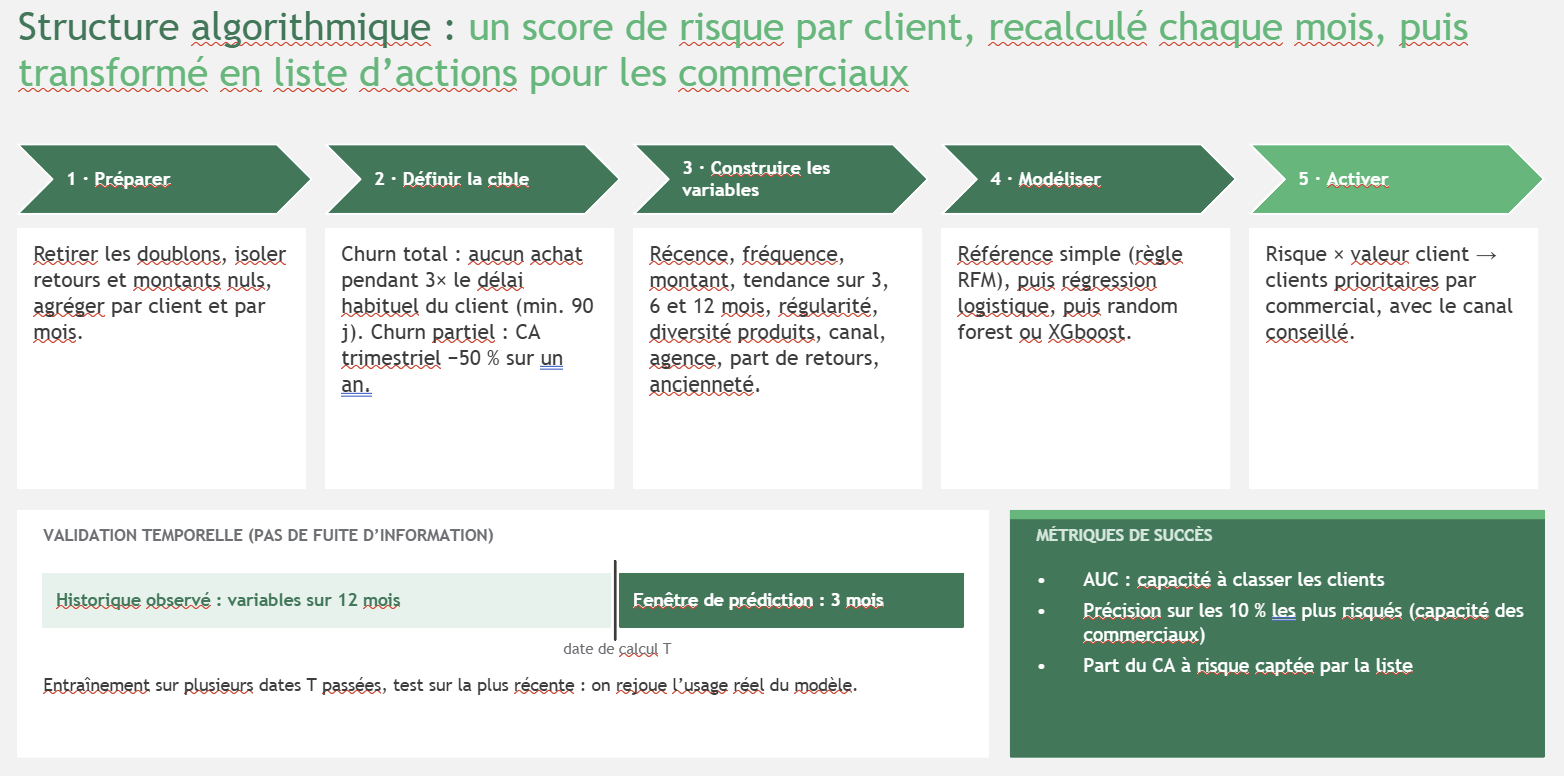

## 1.  Préparation des data d'entrainement

In [28]:
quotidien.select("client_id", "date", "ca_achats", "nb_lignes").describe()

statistic,client_id,date,ca_achats,nb_lignes
str,f64,str,f64,f64
"""count""",7.955289e6,"""7955289""",7.955289e6,7.955289e6
"""null_count""",0.0,"""0""",0.0,0.0
"""mean""",1.1415e6,"""2023-09-21 06:32:00.125441""",1177.526081,7.959398
"""std""",655841.838619,null,4597.771329,12.731304
"""min""",6.0,"""2022-09-22""",-217564.124471,1.0
"""25%""",572235.0,"""2023-03-19""",133.960234,2.0
"""50%""",1.147286e6,"""2023-09-23""",378.02294,4.0
"""75%""",1.710605e6,"""2024-03-21""",1042.4244,9.0
"""max""",2.274517e6,"""2024-09-22""",4.2707e6,3292.0


## Étape 1 — Construire la table de churn

La préparation est regroupée dans `churn_features.py`. La table `quotidien`
contient une ligne par client et jour d'achat. Les lignes de retour, les
quantités non positives et les montants non positifs ou non finis sont exclus.
Les achats valides d'une même journée sont additionnés.

### Population et cible

Le score est calculé **chaque lundi matin, avant les achats du jour**.
Un client doit avoir acheté sur **au moins 6 jours distincts avant le score**.
Le seuil d'inactivité est personnalisé, avec un plancher métier paramétrable :

**Délai de churn = max(90 jours, 3 × intervalle médian historique)**,
arrondi au jour supérieur.

**Échéance = dernier jour d'achat + délai de churn.**

On conserve les clients dont l'échéance courante est comprise entre la date du
score et les **90 jours suivants**. Les clients déjà au-delà de leur échéance
sortent du scoring jusqu'à un nouvel achat ; les clients trop éloignés de leur
échéance y entreront plus tard. Les clients avec moins de 6 jours d'achat
nécessiteront une approche séparée.

La cible décrit la **rupture du cycle d'achat courant**, pas un départ définitif.
L'échéance est figée avec les informations connues à la date du score :

- `churn = 0` si le client rachète au plus tard à cette échéance ;
- `churn = 1` s'il ne rachète pas à temps ;
- `churn = null` tant que la fin de la fenêtre de prédiction de 90 jours
  n'est pas observée, **pour les deux classes**, même si un retour est déjà connu.

Un achat le jour du score ou de l'échéance peut donc donner `churn = 0`, mais
n'entre jamais dans les variables du score de ce lundi.

### Variables disponibles

Toutes les variables utilisent uniquement les achats strictement antérieurs au score :

- **Habitudes et régularité** : nombre de jours d'achat, médiane, moyenne et
  écart-type des intervalles, CV, médiane des 5 derniers intervalles et son
  évolution par rapport à la médiane historique, montant médian par jour d'achat.
- **Situation du client** : ancienneté observée depuis son premier achat,
  fréquence historique ramenée à 30 jours, récence, retard relatif et délai
  restant avant l'échéance.
- **Activité récente** : CA et nombre de jours d'achat sur 30, 90, 180 et 365 jours.
- **Tendances** : comparaison des 90 derniers jours `[T - 90, T[` aux 90 jours
  précédents `[T - 180, T - 90[`, pour le CA, la fréquence et le montant moyen
  par jour d'achat. Une évolution de `-0.5` signifie une baisse de 50 %.
- **Saisonnalité** : mois du score.
- **Produits, agences et canaux**, lorsque ces colonnes sont présentes dans
  `quotidien` : nombres distincts sur les deux périodes de 90 jours, part du
  CA en ligne et évolution de cette part en points de proportion.

Une fenêtre d'activité vide donne un CA et un nombre de jours égaux à zéro.
Les tendances restent nulles si l'ancienneté observée est inférieure à 180 jours
ou si la base de comparaison est nulle : aucune division par zéro ni croissance
artificielle des nouveaux clients. `historique_180j_complet` indique ce recul.
Les anciens parquets sans produits ni canaux restent utilisables ; les variables
correspondantes sont alors absentes, et ne sont pas remplacées par des zéros.

### Disponibilité des cibles

`fin_prediction = date_score + 90 jours`. `fin_observation` est, par défaut,
la dernière date disponible dans la source ; on peut fournir explicitement la
date de clôture de l'extraction. `cible_observable` indique si la fenêtre entière
est couverte. Ces trois colonnes servent à contrôler les cibles et les futurs
découpages temporels, **pas à prédire**.

Les paramètres ci-dessous sont des hypothèses de départ à valider sur les retours
clients et la capacité d'action des commerciaux. Le tableau suivant décrit la
couverture réelle du nouveau jeu de données ; les anciens effectifs ne s'appliquent plus.

In [29]:
from churn_features import construire_lf_churn

lf_churn = construire_lf_churn(
    quotidien,
    min_jours_achat=6,
    facteur_intervalle=3.0,
    min_inactivite_j=90,
    horizon_prediction_j=90,
)

In [30]:
lf_churn.collect_schema().names()

['client_id',
 'dernier_achat',
 'fin_observation',
 'premier_achat',
 'nb_jours_achat',
 'intervalle_median_j',
 'intervalle_std_j',
 'intervalle_recent_median_j',
 'ca_median_jour_achat',
 'intervalle_moyen_j',
 'delai_churn_j',
 'cv_intervalles',
 'evolution_intervalle',
 'echeance',
 'date_score',
 'fin_prediction',
 'recence_j',
 'anciennete_j',
 'delai_avant_echeance_j',
 'cible_observable',
 'mois_score',
 'retard_relatif',
 'frequence_historique_30j',
 'historique_180j_complet',
 'churn',
 'nb_jours_achat_30j',
 'ca_30j',
 'nb_jours_achat_90j',
 'ca_90j',
 'nb_jours_achat_90j_precedents',
 'ca_90j_precedents',
 'nb_jours_achat_180j',
 'ca_180j',
 'nb_jours_achat_365j',
 'ca_365j',
 'evolution_ca_90j',
 'evolution_frequence_90j',
 'ca_moyen_jour_achat_90j',
 'ca_moyen_jour_achat_90j_precedents',
 'evolution_ca_jour_achat_90j']

Analyse sur 5,847,293 lignes à cible connue ; valeurs manquantes exclues par paire.


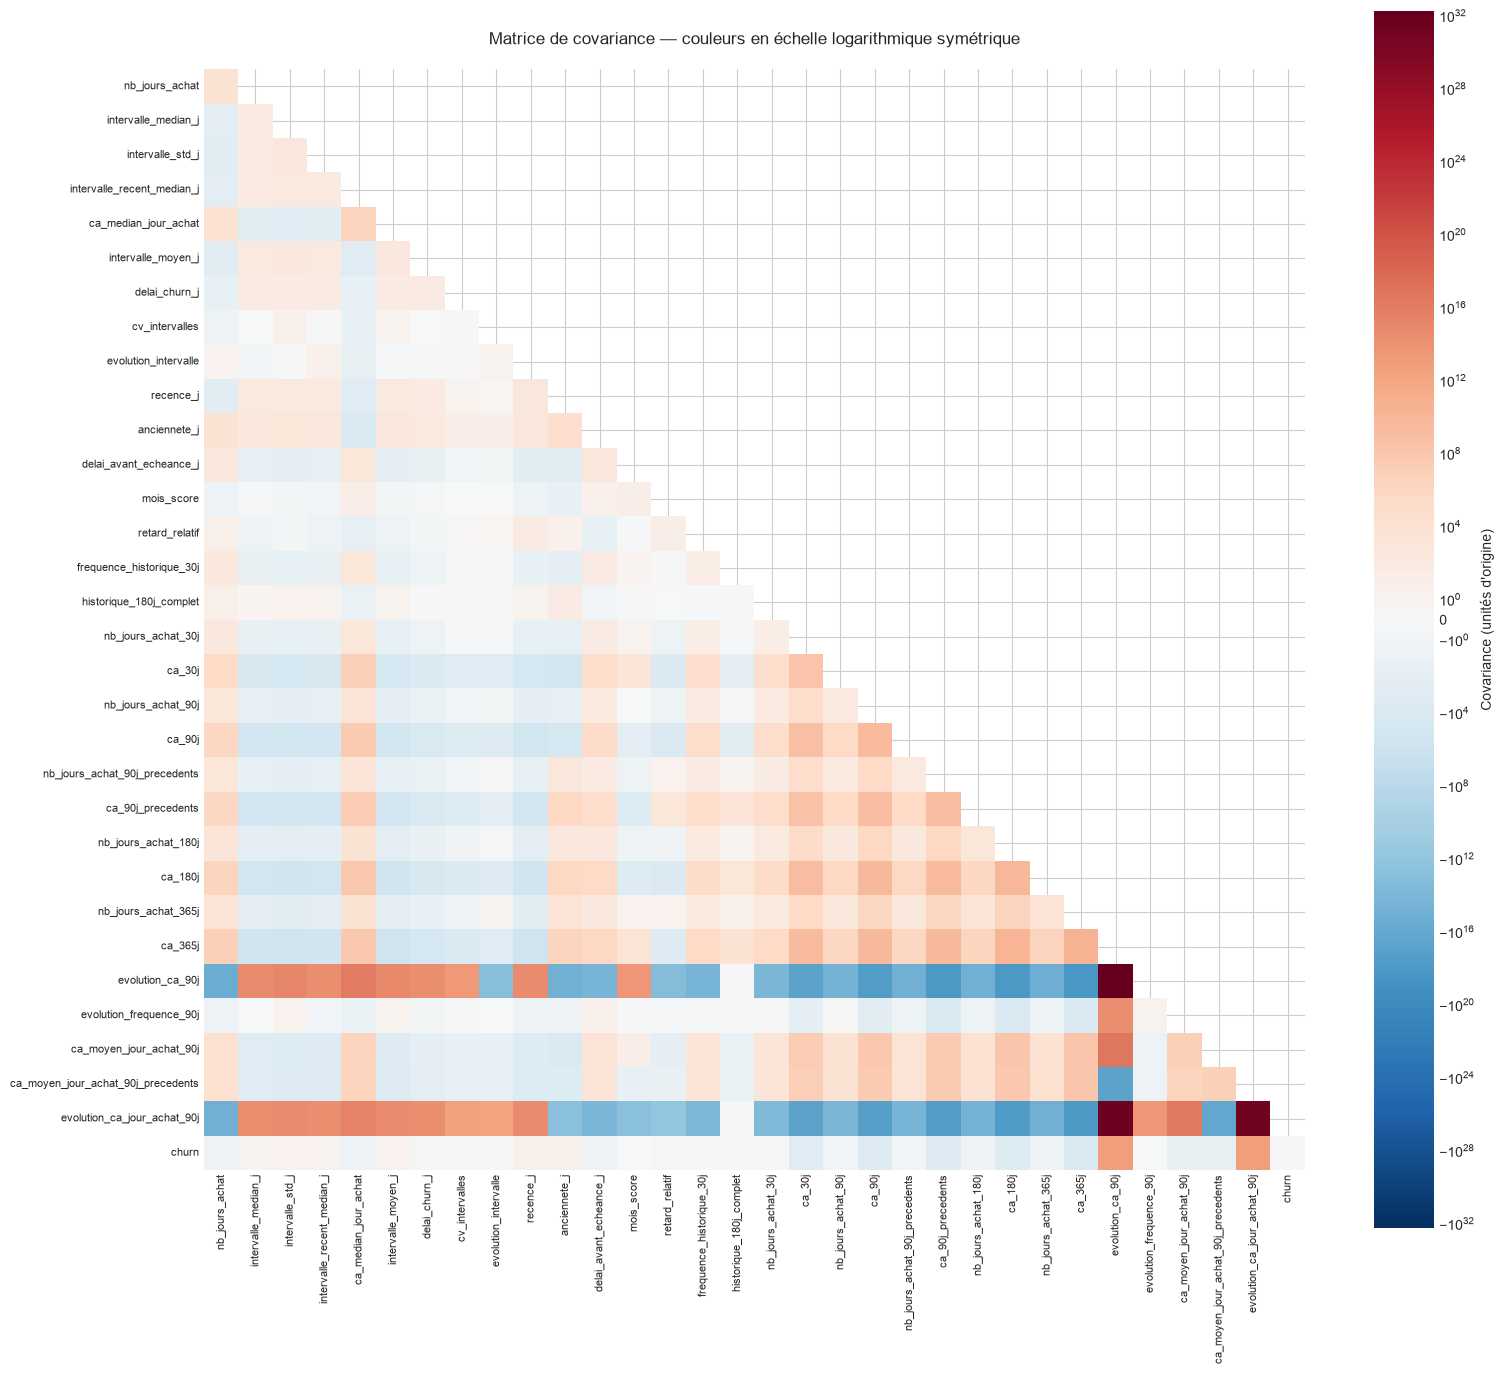

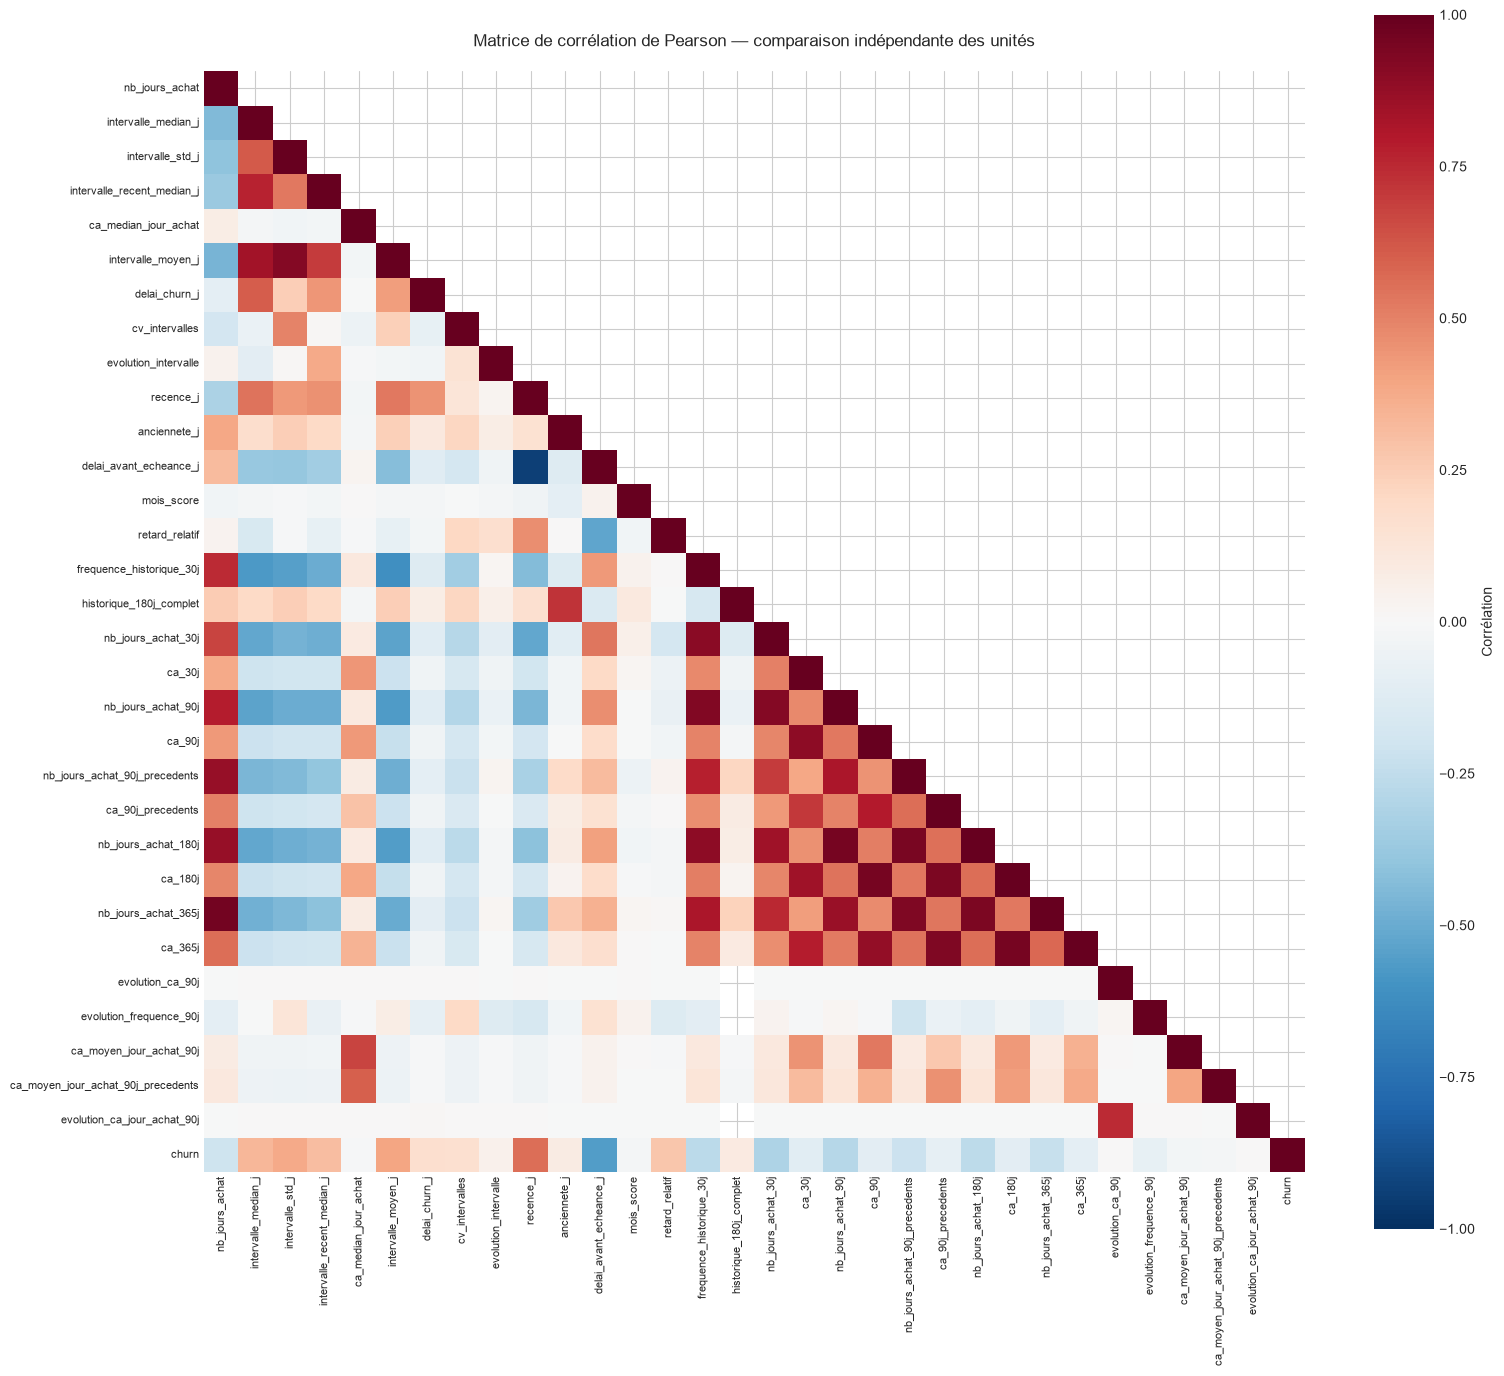

,correlation_avec_churn
recence_j,0.556870
delai_avant_echeance_j,-0.555448
intervalle_moyen_j,0.398408
intervalle_std_j,0.380378
intervalle_median_j,0.328825
nb_jours_achat_30j,-0.306859
intervalle_recent_median_j,0.305971
nb_jours_achat_90j,-0.287166
retard_relatif,0.279474
frequence_historique_30j,-0.271807


In [31]:
# Covariance et corrélation des facteurs avec le churn (cibles observables uniquement).
# Les identifiants, les dates et les métadonnées de disponibilité sont exclus.
# Les associations observées ne démontrent pas une influence causale.
from matplotlib.colors import SymLogNorm

schema_cov = lf_churn.collect_schema()
colonnes_cov = [
    nom for nom, dtype in schema_cov.items()
    if (dtype.is_numeric() or dtype == pl.Boolean)
    and nom not in {"client_id", "cible_observable", "churn"}
] + ["churn"]
paires_cov = [(i, j) for i in range(len(colonnes_cov)) for j in range(i + 1)]

# Agréger dans Polars : seules les matrices, et non toute la table, passent en pandas.
# Les valeurs manquantes sont ignorées paire par paire, sans les remplacer par zéro.
statistiques_cov = (
    lf_churn.filter(pl.col("churn").is_not_null())
    .select(pl.col(colonnes_cov).cast(pl.Float64))
    .select(
        pl.len().alias("nb_lignes"),
        *[
            pl.cov(colonnes_cov[i], colonnes_cov[j]).alias(f"cov_{i}_{j}")
            for i, j in paires_cov
        ],
        *[
            pl.corr(colonnes_cov[i], colonnes_cov[j]).alias(f"corr_{i}_{j}")
            for i, j in paires_cov
        ],
    )
    .collect(engine="streaming")
    .row(0, named=True)
)

matrices_cov = {}
for mesure in ("cov", "corr"):
    valeurs = np.full((len(colonnes_cov), len(colonnes_cov)), np.nan)
    for i, j in paires_cov:
        valeur = statistiques_cov[f"{mesure}_{i}_{j}"]
        valeurs[i, j] = valeurs[j, i] = np.nan if valeur is None else valeur
    matrices_cov[mesure] = pd.DataFrame(valeurs, index=colonnes_cov, columns=colonnes_cov)

variances_cov = pd.Series(np.diag(matrices_cov["cov"]), index=colonnes_cov)
colonnes_variables_cov = variances_cov.index[
    np.isfinite(variances_cov) & (variances_cov > 0)
].tolist()
if statistiques_cov["nb_lignes"] < 2 or "churn" not in colonnes_variables_cov:
    raise ValueError("Il faut des cibles connues et les deux classes de churn pour cette analyse.")

# Retirer les constantes et les colonnes sans variance calculable.
matrice_covariance = matrices_cov["cov"].loc[colonnes_variables_cov, colonnes_variables_cov]
matrice_correlation = matrices_cov["corr"].loc[colonnes_variables_cov, colonnes_variables_cov]
print(f"Analyse sur {statistiques_cov['nb_lignes']:,} lignes à cible connue ; valeurs manquantes exclues par paire.")

limite_cov = np.nanmax(np.abs(matrice_covariance.to_numpy()))
for matrice, titre, options in (
    (
        matrice_covariance,
        "Matrice de covariance — couleurs en échelle logarithmique symétrique",
        {"norm": SymLogNorm(linthresh=1, vmin=-limite_cov, vmax=limite_cov),
         "cbar_kws": {"label": "Covariance (unités d'origine)"}},
    ),
    (
        matrice_correlation,
        "Matrice de corrélation de Pearson — comparaison indépendante des unités",
        {"vmin": -1, "vmax": 1, "cbar_kws": {"label": "Corrélation"}},
    ),
):
    fig, ax = plt.subplots(figsize=(16, 14))
    sns.heatmap(
        matrice, mask=np.triu(np.ones(matrice.shape, dtype=bool), k=1),
        cmap="RdBu_r", square=True, xticklabels=1, yticklabels=1,
        ax=ax, **options,
    )
    ax.set_title(titre, pad=18)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.tick_params(axis="y", labelrotation=0, labelsize=8)
    fig.tight_layout()
    plt.show()

# Le signe indique le sens de l'association ; le classement utilise son intensité.
correlations_churn = matrice_correlation["churn"].drop("churn").dropna()
correlations_churn = correlations_churn.loc[
    correlations_churn.abs().sort_values(ascending=False).index
]
display(correlations_churn.head(15).to_frame("correlation_avec_churn"))

In [20]:
# Une seule collecte pour vérifier la couverture et la maturité des cibles.
couverture_churn = (
    lf_churn.group_by("date_score")
    .agg(
        pl.len().alias("nb_clients"),
        pl.col("churn").count().alias("nb_cibles_connues"),
        pl.col("churn").sum().alias("nb_churn"),
        pl.col("cible_observable").mean().alias("part_cibles_connues"),
        pl.col("churn").mean().alias("taux_churn_cibles_connues"),
    )
    .sort("date_score")
    .collect(engine="streaming")
)

display(couverture_churn.tail(15))

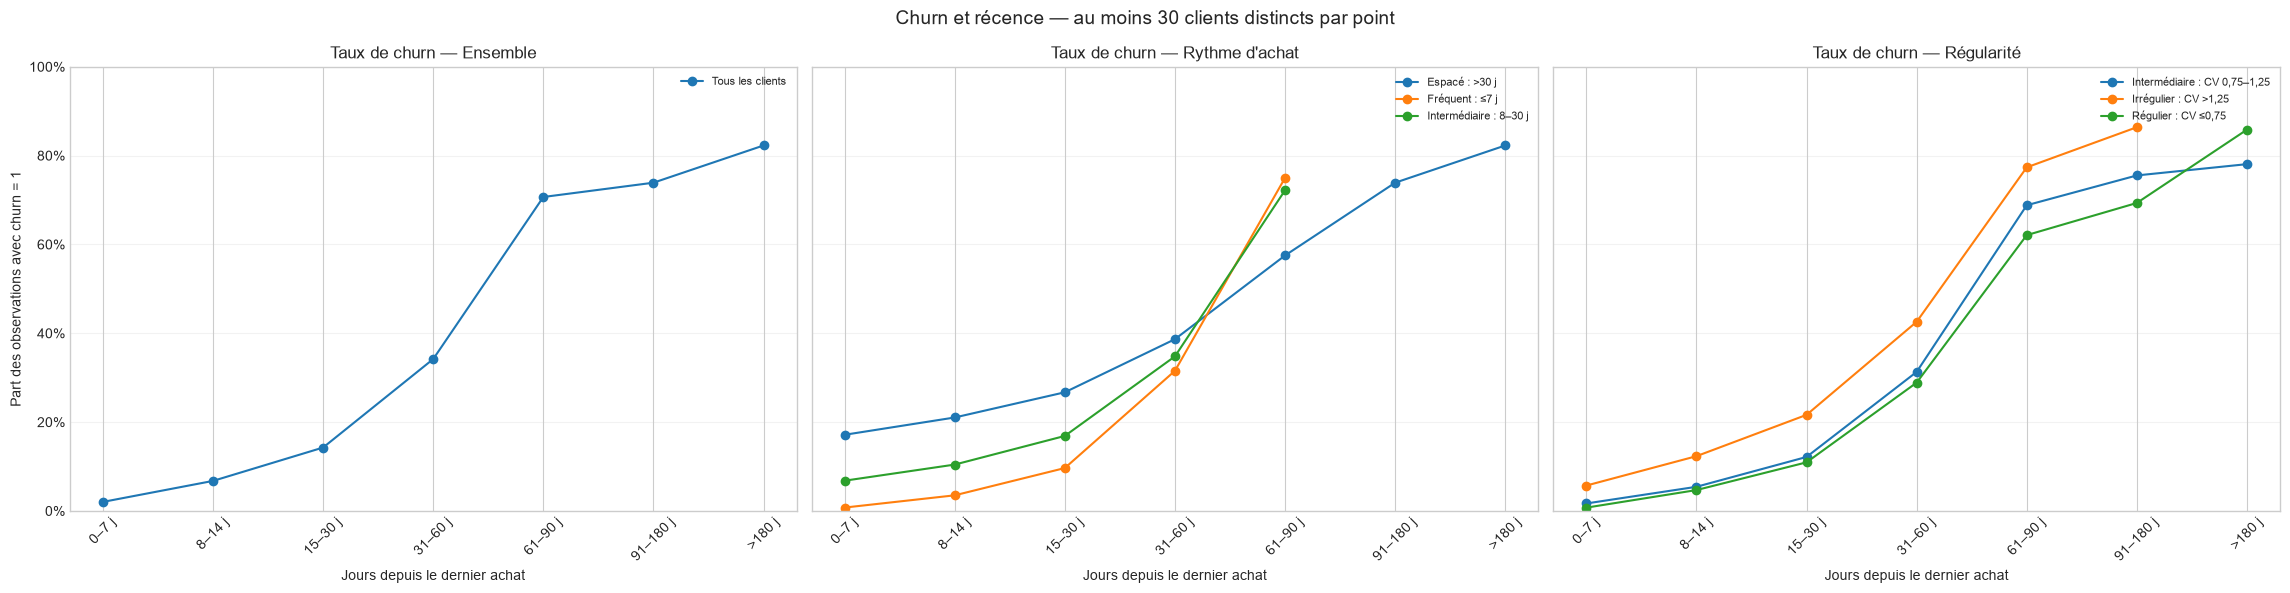

In [19]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

MIN_CLIENTS = 30  # Minimum de clients distincts par point affiché.
BORNES = [7, 14, 30, 60, 90, 180]
TRANCHES = [
    "0–7 j", "8–14 j", "15–30 j", "31–60 j",
    "61–90 j", "91–180 j", ">180 j",
]

tranche_recence = pl.lit(TRANCHES[-1])
for borne, libelle in reversed(list(zip(BORNES, TRANCHES[:-1]))):
    tranche_recence = (
        pl.when(pl.col("recence_j") <= borne)
        .then(pl.lit(libelle))
        .otherwise(tranche_recence)
    )

# Seuils de segmentation descriptifs, modifiables.
base_graphs = (
    lf_churn.filter(pl.col("churn").is_not_null())
    .select(
        "client_id", "churn", "recence_j",
        "intervalle_median_j", "cv_intervalles",
    )
    .with_columns(
        tranche_recence.alias("tranche_recence"),
        pl.lit("Tous les clients").alias("Ensemble"),

        pl.when(pl.col("intervalle_median_j") <= 7)
        .then(pl.lit("Fréquent : ≤7 j"))
        .when(pl.col("intervalle_median_j") <= 30)
        .then(pl.lit("Intermédiaire : 8–30 j"))
        .otherwise(pl.lit("Espacé : >30 j"))
        .alias("Rythme d'achat"),

        pl.when(pl.col("cv_intervalles") <= 0.75)
        .then(pl.lit("Régulier : CV ≤0,75"))
        .when(pl.col("cv_intervalles") <= 1.25)
        .then(pl.lit("Intermédiaire : CV 0,75–1,25"))
        .when(pl.col("cv_intervalles").is_not_null())
        .then(pl.lit("Irrégulier : CV >1,25"))
        .otherwise(None)
        .alias("Régularité"),
    )
)

# Agréger avant de convertir en pandas pour limiter la mémoire utilisée.
bilan_graphs = (
    base_graphs.unpivot(
        on=["Ensemble", "Rythme d'achat", "Régularité"],
        index=["client_id", "churn", "tranche_recence"],
        variable_name="analyse",
        value_name="groupe",
    )
    .drop_nulls("groupe")
    .group_by("analyse", "groupe", "tranche_recence")
    .agg(
        pl.len().alias("nb_observations"),
        pl.col("client_id").n_unique().alias("nb_clients"),
        pl.col("churn").mean().alias("taux_churn"),
    )
    .filter(pl.col("nb_clients") >= MIN_CLIENTS)
    .collect(engine="streaming")
    .to_pandas()
)

if bilan_graphs.empty:
    raise ValueError(
        "Aucun groupe suffisamment fourni : vérifier les cibles ou MIN_CLIENTS."
    )

fig, axes = plt.subplots(1, 3, figsize=(23, 6), sharey=True)

for ax, analyse in zip(axes, ["Ensemble", "Rythme d'achat", "Régularité"]):
    donnees = bilan_graphs[bilan_graphs["analyse"] == analyse]

    for groupe, observations in donnees.groupby("groupe", sort=True):
        serie = observations.set_index("tranche_recence").reindex(TRANCHES)
        # Les groupes insuffisants restent manquants : la courbe s'interrompt.
        ax.plot(TRANCHES, serie["taux_churn"], marker="o", label=groupe)

    ax.set_title(f"Taux de churn — {analyse}")
    ax.set_xlabel("Jours depuis le dernier achat")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)

    if not donnees.empty:
        ax.legend(fontsize=8, loc="best")

axes[0].set_ylabel("Part des observations avec churn = 1")
fig.suptitle(
    f"Churn et récence — au moins {MIN_CLIENTS} clients distincts par point",
    fontsize=14,
)
fig.tight_layout()
plt.show()

## Étape 2 — Entraînement et test chronologique

`entrainer_churn(lf_churn)` applique par défaut le protocole suivant :

| Jeu | Dates des scores | Condition de disponibilité |
|---|---|---|
| Train initial | Octobre 2022 à juillet 2023 | `fin_prediction < 2023-11-01` |
| Validation | Novembre–décembre 2023 | `fin_prediction < 2024-04-01` |
| Test final | Avril–juin 2024 | Fenêtre entièrement observée |

Les dates exactes et les effectifs réellement retenus sont affichés dans
`resultats["periodes"]`. Les bornes de fin sont exclusives et paramétrables.
Les mêmes clients peuvent être présents dans plusieurs périodes : on évalue
les prédictions futures sur le portefeuille existant.

Le nombre d'arbres est choisi par arrêt anticipé sur la validation. Le seuil
de décision maximise le F1 sur cette même validation. Ces décisions sont figées,
puis le modèle final est réentraîné avec toutes les cibles connues avant avril
2024, y compris les scores des périodes intermédiaires devenus exploitables.
Le test ne sert à choisir ni les variables, ni le seuil, ni le nombre d'arbres.

Toutes les variables numériques et booléennes sont utilisées, en excluant
l'identifiant client, la cible et ses métadonnées de disponibilité. Les dates
brutes sont exclues ; `mois_score` reste une variable. Les valeurs manquantes
ne sont pas remplacées par des zéros. L'entraînement n'est pas pondéré par le CA.

Deux lectures des résultats sont séparées :

- `metriques_classification` et `matrice_confusion` utilisent le seuil choisi
  sur la validation. Les lignes de la matrice représentent les classes réelles,
  les colonnes les classes prédites, dans l'ordre `[0, 1]`.
- `metriques_test` compare le modèle à la récence et au retard relatif, avec
  une liste des 5 % de clients les plus risqués **par lundi**. Ce budget est
  paramétrable avec `fraction_alertes` et ne correspond pas nécessairement
  au nombre d'alertes obtenu avec le seuil F1.

Les résultats portent sur des observations client-lundi : un client peut
apparaître plusieurs fois pendant le test.

Variables utilisées : 31
Nombre d'arbres retenu : 157
Seuil choisi sur la validation : 0.193


jeu,nb_lignes,nb_clients,premier_score,dernier_score,derniere_fin_prediction,taux_churn
str,i64,i64,date,date,date,f64
"""train""",2284108,77146,2022-10-03,2023-07-31,2023-10-29,0.086728
"""validation""",607722,83204,2023-11-06,2023-12-25,2024-03-24,0.164338
"""train_final""",3927121,90965,2022-10-03,2024-01-01,2024-03-31,0.113673
"""test""",998544,88345,2024-04-01,2024-06-24,2024-09-22,0.178503


jeu,seuil,precision,rappel,f1,nb_alertes
str,f64,f64,f64,f64,i64
"""validation""",0.192901,0.558152,0.690604,0.617354,123572
"""test""",0.192901,0.506683,0.834961,0.63066,293726


Comparaison avec un budget d'alertes de 5% par lundi


score,average_precision,precision_alertes,rappel_alertes,nb_alertes
str,f64,f64,f64,i64
"""proba_churn""",0.703601,0.861557,0.241362,49934
"""recence_j""",0.6119,0.793768,0.222371,49934
"""retard_relatif""",0.321899,0.49207,0.137851,49934


date_score,nb_clients,nb_cibles_connues,part_cibles_connues
date,u32,u32,f64
2024-04-01,76689,76689,1.0
2024-04-08,76857,76857,1.0
2024-04-15,76998,76998,1.0
2024-04-22,77216,77216,1.0
2024-04-29,77402,77402,1.0
…,…,…,…
2024-05-27,76601,76601,1.0
2024-06-03,76625,76625,1.0
2024-06-10,76511,76511,1.0


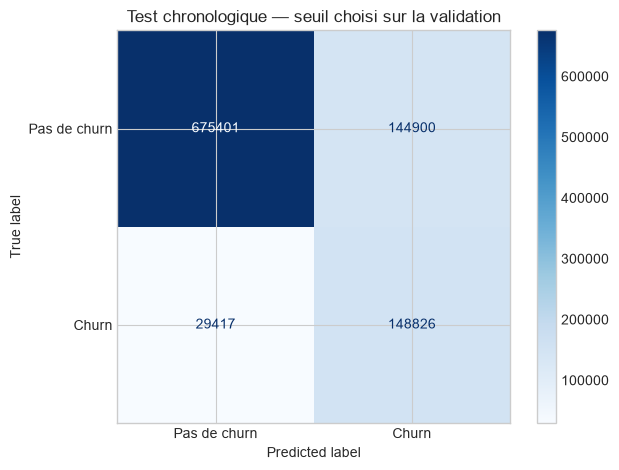

In [32]:
import importlib
import train_churn
from sklearn.metrics import ConfusionMatrixDisplay

importlib.reload(train_churn)
resultats = train_churn.entrainer_churn(lf_churn)
modele = resultats["modele"]
variables = resultats["variables"]

print(f"Variables utilisées : {len(variables)}")
print(f"Nombre d'arbres retenu : {resultats['nb_arbres']}")
print(f"Seuil choisi sur la validation : {resultats['seuil_decision']:.3f}")
display(resultats["periodes"])
display(resultats["metriques_classification"])
print(f"Comparaison avec un budget d'alertes de {resultats['fraction_alertes']:.0%} par lundi")
display(resultats["metriques_test"])
display(resultats["couverture_test"])

ConfusionMatrixDisplay(
    confusion_matrix=resultats["matrice_confusion"],
    display_labels=["Pas de churn", "Churn"],
).plot(cmap="Blues", values_format="d")
plt.title("Test chronologique — seuil choisi sur la validation")
plt.tight_layout()
plt.show()

In [33]:
resultats['matrice_confusion']

array([[675401, 144900],
       [ 29417, 148826]])

In [34]:
top5_par_lundi = (
    resultats["predictions_test"]
    .sort(
        ["date_score", "proba_churn", "client_id"],
        descending=[False, True, False],
    )
    .filter(
        pl.int_range(pl.len()).over("date_score")
        < (pl.len().over("date_score") * 0.05).ceil()
    )
)

bilan_top5 = (
    top5_par_lundi
    .group_by("date_score")
    .agg(
        pl.len().alias("nb_clients_selectionnes"),
        pl.col("churn").sum().alias("nb_churners_reels"),
        (100 * pl.col("churn").mean())
        .round(2)
        .alias("proportion_churners_pct"),
    )
    .sort("date_score")
)

display(bilan_top5)

date_score,nb_clients_selectionnes,nb_churners_reels,proportion_churners_pct
date,u32,i64,f64
2024-04-01,3835,3265,85.14
2024-04-08,3843,3282,85.4
2024-04-15,3850,3333,86.57
2024-04-22,3861,3428,88.79
2024-04-29,3871,3522,90.98
…,…,…,…
2024-05-27,3831,3196,83.42
2024-06-03,3832,3211,83.79
2024-06-10,3826,3244,84.79


In [35]:
boutiques_par_client = (
    lf.filter(
        pl.col("client_id").is_not_null()
        & pl.col("branch_id").is_not_null()
        & pl.col("quantity").is_finite()
        & (pl.col("quantity") > 0)
        & pl.col("sales_net").is_finite()
        & (pl.col("sales_net") > 0)
    )
    .group_by("client_id")
    .agg(
        pl.col("branch_id").n_unique().alias("nb_boutiques")
    )
)

resume_boutiques = (
    boutiques_par_client
    .select(
        pl.len().alias("nb_clients_total"),
        (pl.col("nb_boutiques") >= 2)
        .sum()
        .alias("nb_clients_multiboutiques"),
        (100 * (pl.col("nb_boutiques") >= 2).mean())
        .round(2)
        .alias("proportion_multiboutiques_pct"),
    )
    .collect(engine="streaming")
)

display(resume_boutiques)

nb_clients_total,nb_clients_multiboutiques,proportion_multiboutiques_pct
u32,u32,f64
170586,83110,48.72


# Estimation du CA gagné

In [36]:
from simulation_appels import simuler_appels

simulation = simuler_appels(
    ventes=lf,
    predictions=resultats["predictions_test"],
    fraction_appels=0.05,
    taux_recuperation=0.10,
    scenarios_recuperation=(0.05, 0.10, 0.20),
    fenetre_ca_j=365,
    horizon_gain_j=90,
    delai_rappel_j=90,
    capacite_max_appels=None,  # Mettre 20 pour plafonner à 20 appels/boutique/lundi.
)

# Estimation globale selon les hypothèses de récupération.
display(simulation["scenarios"])

# Résultats par semaine et par boutique responsable.
display(simulation["bilan_hebdomadaire"])
display(
    simulation["bilan_par_boutique"]
    .sort("ca_incremental_estime", descending=True, nulls_last=True)
)

# Liste des clients à appeler, dans l'ordre de priorité.
appels = simulation["appels"]
display(
    appels.select(
        "date_score",
        "boutique_responsable",
        "client_id",
        "proba_churn",
        "ca_reference_client",
        "score_priorite",
        "rang_appel",
    ).head(30)
)

taux_recuperation,nb_appels,nb_clients_distincts,nb_appels_evaluables,nb_churners_appeles_evaluables,ca_manquant_churn_evaluable,nb_recuperations_estimees,ca_incremental_estime
f64,u32,u32,u32,i64,f64,f64,f64
0.0,46961,46961,46961,14297,4.0436e7,0.0,0.0
0.05,46961,46961,46961,14297,4.0436e7,714.85,2.0218e6
0.1,46961,46961,46961,14297,4.0436e7,1429.7,4.0436e6
0.2,46961,46961,46961,14297,4.0436e7,2859.4,8.0871e6


date_score,nb_appels,nb_clients_distincts,nb_appels_evaluables,nb_churners_appeles_evaluables,ca_manquant_churn_evaluable,nb_recuperations_estimees,ca_incremental_estime
date,u32,u32,u32,i64,f64,f64,f64
2024-04-01,3599,3599,3599,1989,1.6037e7,198.9,1.6037e6
2024-04-08,3615,3615,3615,1568,5.0944e6,156.8,509441.70957
2024-04-15,3631,3631,3631,1340,3.5112e6,134.0,351116.554109
2024-04-22,3633,3633,3633,1193,3.0482e6,119.3,304819.460433
2024-04-29,3644,3644,3644,1009,2.3697e6,100.9,236969.741797
…,…,…,…,…,…,…,…
2024-05-27,3601,3601,3601,976,1.4724e6,97.6,147243.689621
2024-06-03,3609,3609,3609,1138,1.4349e6,113.8,143488.21131
2024-06-10,3601,3601,3601,1220,1.3031e6,122.0,130310.194219


boutique_responsable,nb_appels,nb_clients_distincts,nb_appels_evaluables,nb_churners_appeles_evaluables,ca_manquant_churn_evaluable,nb_recuperations_estimees,ca_incremental_estime
i64,u32,u32,u32,i64,f64,f64,f64
742,117,117,117,41,483090.112057,4.1,48309.011206
3318,255,255,255,61,482756.06667,6.1,48275.606667
5012,220,220,220,55,390327.028717,5.5,39032.702872
3225,227,227,227,56,351649.286125,5.6,35164.928613
9746,130,130,130,39,344911.821831,3.9,34491.182183
…,…,…,…,…,…,…,…
1292,26,26,26,8,9108.11474,0.8,910.811474
791,52,52,52,16,8441.105401,1.6,844.11054
5167,70,70,70,8,7730.646658,0.8,773.064666


date_score,boutique_responsable,client_id,proba_churn,ca_reference_client,score_priorite,rang_appel
date,i64,i64,f64,f64,f64,i64
2024-04-01,20,1969486,0.440404,53787.25697,23688.129418,1
2024-04-01,20,1465186,0.309183,63883.695929,19751.777606,2
2024-04-01,20,262925,0.769032,18833.889327,14483.862482,3
2024-04-01,20,25923,0.31238,35820.782265,11189.685856,4
2024-04-01,20,1901613,0.68484,14428.840531,9881.442329,5
…,…,…,…,…,…,…
2024-04-01,210,300308,0.588737,46779.106213,27540.605108,1
2024-04-01,210,634296,0.768414,19329.574922,14853.115229,2
2024-04-01,210,1363048,0.348722,20585.908169,7178.756838,3


In [37]:
import joblib
from pathlib import Path

chemin = Path("data/resultats_churn.joblib")
joblib.dump(resultats, chemin, compress=3)

print(f"Sauvegarde : {chemin.resolve()}")

Sauvegarde : C:\Users\gwenm\Documents\loupi\3ACS\M2AD\EDC 3 BCGX\code\data\resultats_churn.joblib


In [ ]:
resultats = joblib.load("data/resultats_churn.joblib")

modele = resultats["modele"]
variables = resultats["variables"]
seuil = resultats["seuil_decision"]

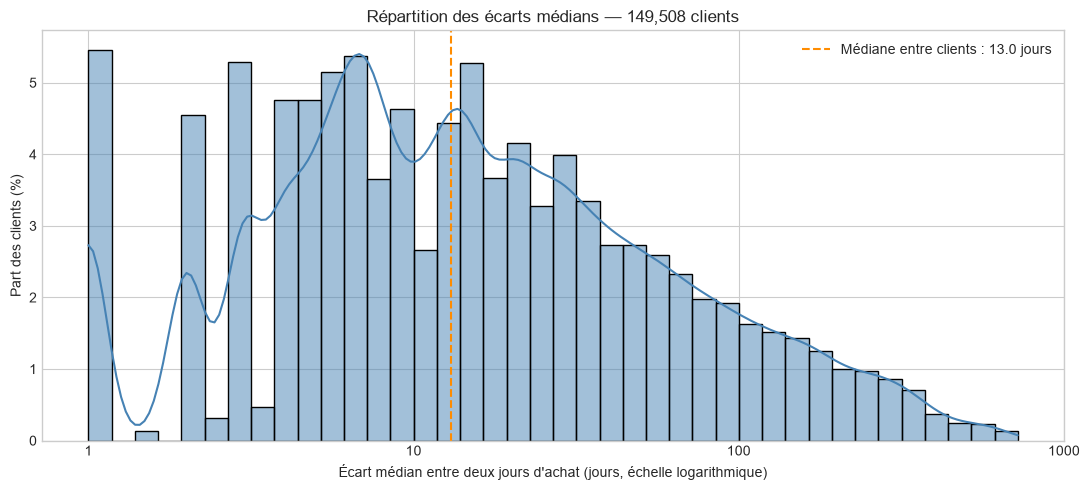

In [38]:
MIN_JOURS_ACHAT = 2  # Mettre 6 pour retenir des historiques plus fournis.

ecarts_clients = (
    quotidien
    .select("client_id", "date")
    .sort(["client_id", "date"])
    .with_columns(
        pl.col("date")
        .diff()
        .over("client_id")
        .dt.total_days()
        .alias("ecart_j")
    )
    .group_by("client_id")
    .agg(
        pl.len().alias("nb_jours_achat"),
        pl.col("ecart_j").median().alias("ecart_median_j"),
    )
    .filter(
        (pl.col("nb_jours_achat") >= MIN_JOURS_ACHAT)
        & (pl.col("ecart_median_j") > 0)
    )
    .collect(engine="streaming")
)

if ecarts_clients.is_empty():
    raise ValueError("Pas assez d'achats pour calculer les écarts.")

valeurs = ecarts_clients["ecart_median_j"]
mediane = valeurs.median()

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    x=valeurs.to_numpy(),
    bins=40,
    stat="percent",
    kde=valeurs.n_unique() > 1,
    log_scale=True,
    color="steelblue",
    ax=ax,
)

ax.axvline(
    mediane,
    color="darkorange",
    linestyle="--",
    label=f"Médiane entre clients : {mediane:.1f} jours",
)

ax.set(
    title=f"Répartition des écarts médians — {ecarts_clients.height:,} clients",
    xlabel="Écart médian entre deux jours d'achat (jours, échelle logarithmique)",
    ylabel="Part des clients (%)",
)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.legend()
plt.tight_layout()
plt.show()

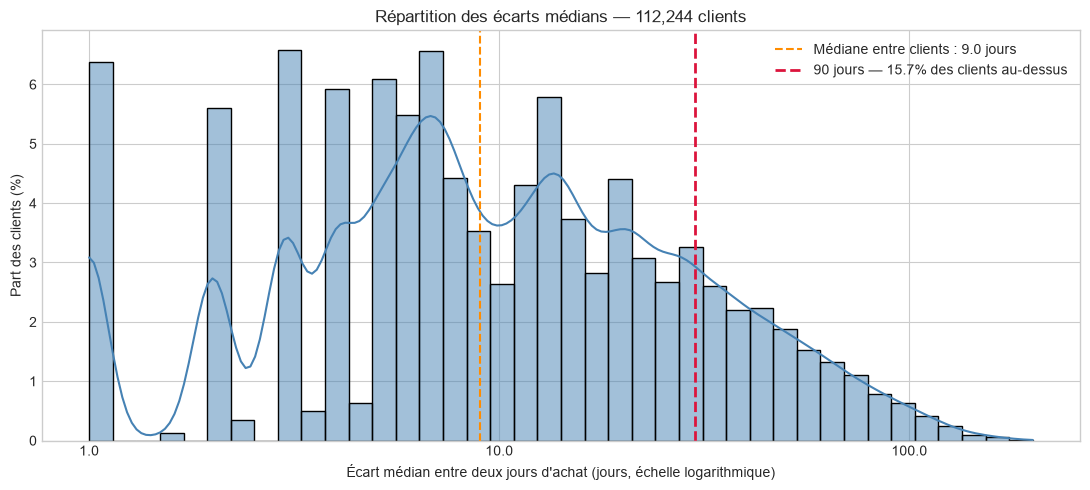

Clients avec une médiane > 90 jours : 17,620 / 112,244 (15.70%)
CA cumulé de ces clients : 112,014,598 €
Part du CA du périmètre retenu : 1.21%


In [41]:
MIN_JOURS_ACHAT = 6
SEUIL_JOURS = 30

ecarts_clients = (
    quotidien
    .select("client_id", "date", "ca_achats")
    .sort(["client_id", "date"])
    .with_columns(
        pl.col("date")
        .diff()
        .over("client_id")
        .dt.total_days()
        .alias("ecart_j")
    )
    .group_by("client_id")
    .agg(
        pl.len().alias("nb_jours_achat"),
        pl.col("ecart_j").median().alias("ecart_median_j"),
        pl.col("ca_achats").sum().alias("ca_total"),
    )
    .filter(
        (pl.col("nb_jours_achat") >= MIN_JOURS_ACHAT)
        & (pl.col("ecart_median_j") > 0)
    )
    .collect(engine="streaming")
)

if ecarts_clients.is_empty():
    raise ValueError("Pas assez d'achats pour calculer les écarts.")

# Clients dont la médiane est strictement supérieure à 90 jours.
clients_sup90 = ecarts_clients.filter(
    pl.col("ecart_median_j") > SEUIL_JOURS
)

part_clients = clients_sup90.height / ecarts_clients.height
ca_sup90 = clients_sup90["ca_total"].sum()
ca_perimetre = ecarts_clients["ca_total"].sum()
part_ca = ca_sup90 / ca_perimetre if ca_perimetre > 0 else None

valeurs = ecarts_clients["ecart_median_j"]

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    x=valeurs.to_numpy(),
    bins=40,
    stat="percent",
    kde=valeurs.n_unique() > 1,
    log_scale=True,
    color="steelblue",
    ax=ax,
)

ax.axvline(
    valeurs.median(),
    color="darkorange",
    linestyle="--",
    label=f"Médiane entre clients : {valeurs.median():.1f} jours",
)
ax.axvline(
    SEUIL_JOURS,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"90 jours — {part_clients:.1%} des clients au-dessus",
)

ax.set(
    title=f"Répartition des écarts médians — {ecarts_clients.height:,} clients",
    xlabel="Écart médian entre deux jours d'achat (jours, échelle logarithmique)",
    ylabel="Part des clients (%)",
)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.legend()
plt.tight_layout()
plt.show()

print(
    f"Clients avec une médiane > 90 jours : "
    f"{clients_sup90.height:,} / {ecarts_clients.height:,} "
    f"({part_clients:.2%})"
)
print(f"CA cumulé de ces clients : {ca_sup90:,.0f} €")

if part_ca is not None:
    print(f"Part du CA du périmètre retenu : {part_ca:.2%}")

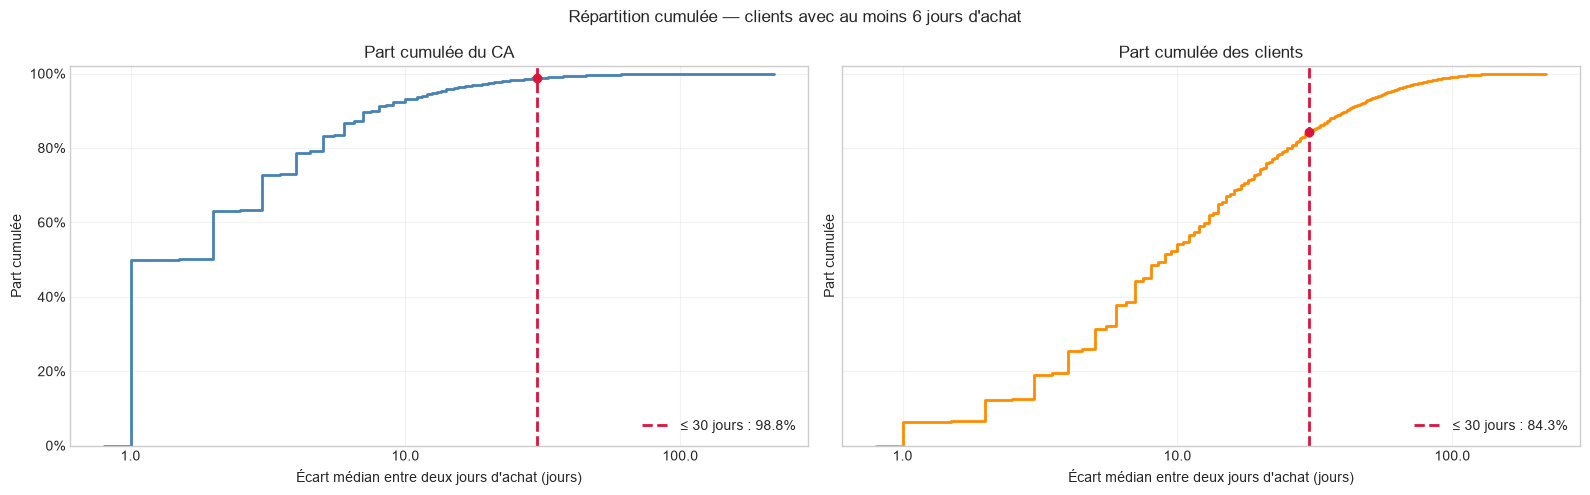

Médiane > 30 jours : 15.70% des clients
Part du CA rapportée par ces clients : 1.21%


In [43]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, ScalarFormatter

MIN_JOURS_ACHAT = 6
SEUIL_JOURS = 30

base = ecarts_clients.filter(
    pl.col("nb_jours_achat") >= MIN_JOURS_ACHAT
)

if base.is_empty() or base["ca_total"].sum() <= 0:
    raise ValueError("Pas assez de clients ou de CA pour tracer les courbes.")

# Regrouper les médianes identiques avant de calculer les cumuls.
courbes = (
    base.group_by("ecart_median_j")
    .agg(
        pl.len().alias("nb_clients"),
        pl.col("ca_total").sum().alias("ca"),
    )
    .sort("ecart_median_j")
    .with_columns(
        (
            pl.col("nb_clients").cum_sum()
            / pl.col("nb_clients").sum()
        ).alias("part_clients_cumulee"),
        (
            pl.col("ca").cum_sum()
            / pl.col("ca").sum()
        ).alias("part_ca_cumulee"),
    )
)

sous_seuil = base.filter(pl.col("ecart_median_j") <= SEUIL_JOURS)
part_clients_90 = sous_seuil.height / base.height
part_ca_90 = sous_seuil["ca_total"].sum() / base["ca_total"].sum()

x = courbes["ecart_median_j"].to_numpy()

# Prolonger les courbes à 0 % avant la première médiane et à 100 % après.
x_trace = np.r_[
    min(x[0], SEUIL_JOURS) * 0.8,
    x,
    max(x[-1], SEUIL_JOURS) * 1.1,
]

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharex=True, sharey=True)

for ax, colonne, titre, part_90, couleur in [
    (
        axes[0], "part_ca_cumulee",
        "Part cumulée du CA", part_ca_90, "steelblue",
    ),
    (
        axes[1], "part_clients_cumulee",
        "Part cumulée des clients", part_clients_90, "darkorange",
    ),
]:
    y_trace = np.r_[0, courbes[colonne].to_numpy(), 1]

    ax.step(x_trace, y_trace, where="post", color=couleur, linewidth=2)
    ax.axvline(
        SEUIL_JOURS,
        color="crimson",
        linestyle="--",
        linewidth=2,
        label=f"≤ 30 jours : {part_90:.1%}",
    )
    ax.scatter([SEUIL_JOURS], [part_90], color="crimson", zorder=5)

    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylim(0, 1.02)
    ax.set_title(titre)
    ax.set_xlabel("Écart médian entre deux jours d'achat (jours)")
    ax.set_ylabel("Part cumulée")
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")

fig.suptitle(
    f"Répartition cumulée — clients avec au moins {MIN_JOURS_ACHAT} jours d'achat"
)
plt.tight_layout()
plt.show()

print(f"Médiane > 30 jours : {1 - part_clients_90:.2%} des clients")
print(f"Part du CA rapportée par ces clients : {1 - part_ca_90:.2%}")
